In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
df = pd.read_csv("uber.csv")

df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,52:06.0,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,04:56.0,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,45:00.0,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,22:21.0,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,47:00.0,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [3]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Description:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (200000, 9)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  str    
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  str    
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), str(2)
memory usage: 13.7 MB

Statistical Description:
         Unnamed: 0    fare_amount  pickup_longitude  pickup_latitude  \
count  2.000000e+05  200000.000000     200000.000000    200000.000000   
mean   2.771250e+07      11.359955        -72.527638        39.935885   
std    1.

In [4]:
# Remove unnecessary column
df = df.drop('key', axis=1)

# Convert pickup_datetime into datetime format
df['pickup_datetime'] = pd.to_datetime(
    df['pickup_datetime'], errors='coerce', utc=True
)

# Remove missing values
df = df.dropna()

# Remove invalid fare amounts
df = df[df['fare_amount'] > 0]

# Remove invalid geographical coordinates
df = df[
    df['pickup_latitude'].between(-90, 90) &
    df['dropoff_latitude'].between(-90, 90) &
    df['pickup_longitude'].between(-180, 180) &
    df['dropoff_longitude'].between(-180, 180)
]

# Remove invalid passenger counts
df = df[df['passenger_count'].between(1, 6)]

df = df.reset_index(drop=True)

print("Cleaned Dataset Shape:", df.shape)

Cleaned Dataset Shape: (199256, 8)


In [5]:
def haversine_distance(lat1, lon1, lat2, lon2):

    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2)**2 +
        np.cos(lat1) * np.cos(lat2) *
        np.sin(dlon / 2)**2
    )

    c = 2 * np.arcsin(np.sqrt(a))

    return 6371 * c


df['distance_km'] = haversine_distance(
    df['pickup_latitude'],
    df['pickup_longitude'],
    df['dropoff_latitude'],
    df['dropoff_longitude']
)

df.head()

,Unnamed: 0,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,distance_km
0,24238194,7.5,2015-05-07 19:52:06+00:00,-73.999817,40.738354,-73.999512,40.723217,1,1.683323
1,27835199,7.7,2009-07-17 20:04:56+00:00,-73.994355,40.728225,-73.994710,40.750325,1,2.457590
2,44984355,12.9,2009-08-24 21:45:00+00:00,-74.005043,40.740770,-73.962565,40.772647,1,5.036377
3,25894730,5.3,2009-06-26 08:22:21+00:00,-73.976124,40.790844,-73.965316,40.803349,3,1.661683
4,17610152,16.0,2014-08-28 17:47:00+00:00,-73.925023,40.744085,-73.973082,40.761247,5,4.475450


In [6]:
df['hour'] = df['pickup_datetime'].dt.hour
df['day'] = df['pickup_datetime'].dt.day
df['month'] = df['pickup_datetime'].dt.month
df['day_of_week'] = df['pickup_datetime'].dt.dayofweek

df = df.drop('pickup_datetime', axis=1)

df.head()

/tmp/ipykernel_21632/4174723179.py:4: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['day_of_week'] = df['pickup_datetime'].dt.dayofweek


,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,distance_km,hour,day,month,day_of_week
0,24238194,7.5,-73.999817,40.738354,-73.999512,40.723217,1,1.683323,19,7,5,3
1,27835199,7.7,-73.994355,40.728225,-73.994710,40.750325,1,2.457590,20,17,7,4
2,44984355,12.9,-74.005043,40.740770,-73.962565,40.772647,1,5.036377,21,24,8,0
3,25894730,5.3,-73.976124,40.790844,-73.965316,40.803349,3,1.661683,8,26,6,4
4,17610152,16.0,-73.925023,40.744085,-73.973082,40.761247,5,4.475450,17,28,8,3


In [7]:
X = df[
    [
        'pickup_longitude',
        'pickup_latitude',
        'dropoff_longitude',
        'dropoff_latitude',
        'passenger_count',
        'distance_km',
        'hour',
        'day',
        'month',
        'day_of_week'
    ]
]

y = df['fare_amount']

print("Input Shape:", X.shape)
print("Output Shape:", y.shape)

Input Shape: (199256, 10)
Output Shape: (199256,)


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (159404, 10)
Testing Data: (39852, 10)


In [9]:
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

print("Linear Regression Training Completed")

Linear Regression Training Completed


In [10]:
linear_mse = mean_squared_error(
    y_test, linear_predictions
)

linear_rmse = np.sqrt(linear_mse)

linear_r2 = r2_score(
    y_test, linear_predictions
)

print("Linear Regression Results")
print("MSE:", linear_mse)
print("RMSE:", linear_rmse)
print("R2 Score:", linear_r2)

Linear Regression Results
MSE: 96.8328599488868
RMSE: 9.840368892927074
R2 Score: 0.0020685515951731626


In [11]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

print("Random Forest Training Completed")

Random Forest Training Completed


In [12]:
rf_mse = mean_squared_error(
    y_test, rf_predictions
)

rf_rmse = np.sqrt(rf_mse)

rf_r2 = r2_score(
    y_test, rf_predictions
)

print("Random Forest Regression Results")
print("MSE:", rf_mse)
print("RMSE:", rf_rmse)
print("R2 Score:", rf_r2)

Random Forest Regression Results
MSE: 21.89028882854396
RMSE: 4.678705892503178
R2 Score: 0.7744050144940493


In [13]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'MSE': [linear_mse, rf_mse],
    'RMSE': [linear_rmse, rf_rmse],
    'R2 Score': [linear_r2, rf_r2]
})

print(results)

               Model        MSE      RMSE  R2 Score
0  Linear Regression  96.832860  9.840369  0.002069
1      Random Forest  21.890289  4.678706  0.774405


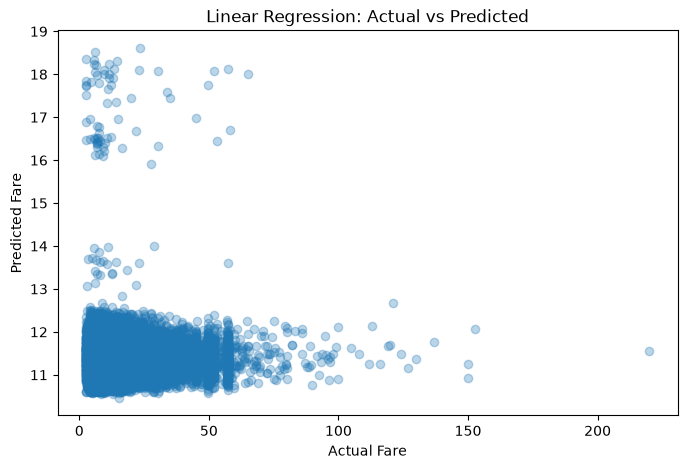

In [14]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, linear_predictions, alpha=0.3)

plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")
plt.title("Linear Regression: Actual vs Predicted")

plt.show()

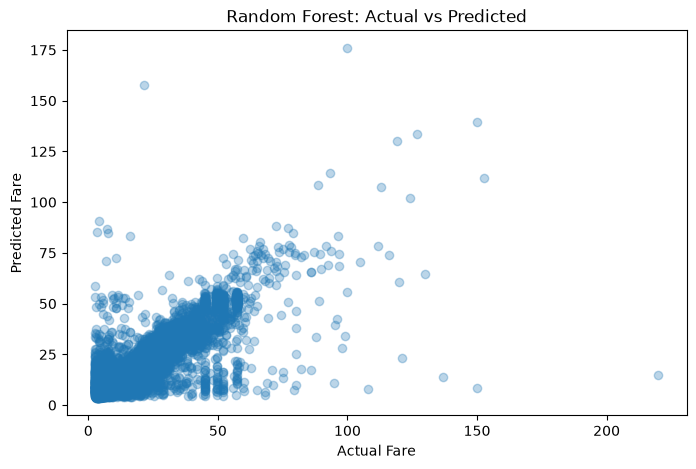

In [15]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, rf_predictions, alpha=0.3)

plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")
plt.title("Random Forest: Actual vs Predicted")

plt.show()